# Improved Model Validation

The objective of this model is to statistically validate and evaluate the model.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import altair as alt
import pandas as pd
import numpy as np
import sys

from sklearn.model_selection import GroupKFold
from scipy.optimize import minimize_scalar
import statsmodels.api as sm
import scipy.stats as stats

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "tumorgrowth-processed.csv"
EXPORT_PATH = PROJECT_ROOT / "figures"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.models.improved_model import simulate_tumor
from src.models.fit_improved_model import fit_model, truncate_dataset

In [2]:
# Load data
data = pd.read_csv(DATA_PATH)

Before performing all the analysis it is necessary to fit the model to the available data, which will be done in the following:

In [3]:
%%time
seed = 23 ; maxiter = 10 ; popsize = 5

group_results, mouse_results = fit_model(data, seed, maxiter, popsize, 15)

CPU times: total: 3min 8s
Wall time: 3min 18s


Since the optimization performed during model training minimized log-MSE, the residuals must also be computed also the log-scale ($res_{i,t} = \log(Y_{obs,i,t}) - \log(Y_{pred,i,t})$. The Gaussian prior penalty is not included in the calculation because it is a mathematical tool used during optimization to regularize the parameter estimates.

The following function will add the predicted values and log-loss for each observation in the original dataset (only for $Day \leq 15$, which corresponds with the training window):

In [4]:
def add_predictions(data: pd.DataFrame, mouse_results: pd.DataFrame, group_results: pd.DataFrame, max_day: int) -> pd.DataFrame:
    """
    Adds 'Pred_Size' and 'Log_Residual' columns to the original dataset.

    Input:
    ----------
    data: Original dataset (pd.DataFrame)
    mouse_results: Dataset (pd.DataFrame) storing the parameters obtained after fitting the Model to the available data

    Output:
    ----------
    df: pd.DataFrame copy of the original dataset with the extra columns 'Pred_Size' and 'Log_Residual'
    """
    df = data.copy()
    df = truncate_dataset(df, max_day)

    df["Pred_Size"] = np.nan

    for mouse_id in df["ID"].unique():
        mouse_mask = df["ID"] == mouse_id
        mouse_df = df.loc[mouse_mask]

        T_obs = mouse_df["Size"].to_numpy()
        T0 = T_obs[0]
        times = mouse_df["Day"].to_numpy()
        grp = mouse_df["Group"].iloc[0]
        D = grp > 1
        
        r_i = mouse_results.loc[mouse_results["ID"] == mouse_id, "r_id"].iloc[0]
        K = group_results["K"].iloc[0]
        al = group_results.loc[group_results["Group"]==grp, "al"].iloc[0]

        sim_df = simulate_tumor(
            T0=T0,
            r=r_i,
            K=K,
            al=al,
            times=times,
            D=D
        )

        df.loc[mouse_mask, "Pred_Size"] = sim_df["Size"].values

    df["Log_Residual"] = np.log(df["Size"]) - np.log(df["Pred_Size"])
    return df

df = add_predictions(data, mouse_results, group_results, 15)
df.head()

,Grp,Group,ID,Day,Size,Baseline,RTV,Pred_Size,Log_Residual
0,1.CTR,1,101,0,41.8,41.8,1.000000,41.800000,0.000000
1,1.CTR,1,101,3,85.0,41.8,2.033493,90.689043,-0.064785
2,1.CTR,1,101,4,114.0,41.8,2.727273,117.217731,-0.027835
3,1.CTR,1,101,5,162.3,41.8,3.882775,151.326443,0.070007
4,1.CTR,1,101,6,178.3,41.8,4.265550,195.061130,-0.089845


## Residual Analysis

#### Residuals vs. Time

This plot tests the assumption of temporal independence and structural time-invariance. If the model is valid, residuals should scatter randomly around the zero-line at all time points. This is the most critical validation step, since violating it means that the model does not capture the dynamics of tumor growth ($E[\varepsilon \mid t] \neq 0$) and, therefore, that the estimated parameters are statistically biased.

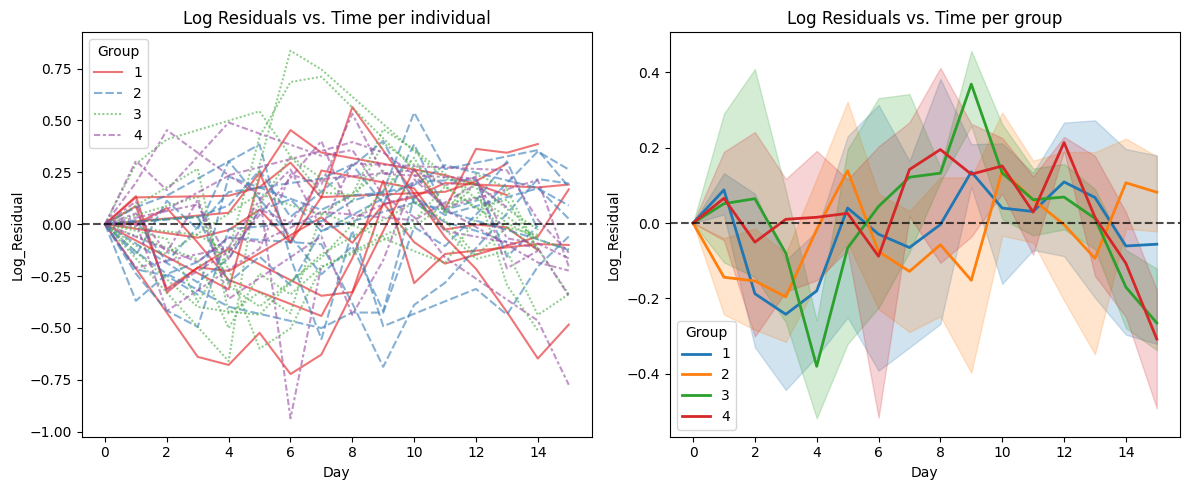

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(data=df, x="Day", y="Log_Residual", hue="Group", style="Group", units="ID", estimator=None, alpha=0.6, palette="Set1", legend="full", ax=ax1)
ax1.set_title("Log Residuals vs. Time per individual")
ax1.axhline(0, color="black", linestyle="--", alpha=0.7)

sns.lineplot(data=df, x="Day", y="Log_Residual", hue="Group", palette="tab10", linewidth=2, ax=ax2)
ax2.set_title("Log Residuals vs. Time per group")
ax2.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.tight_layout()
fig.savefig(EXPORT_PATH / "fig17.png", dpi=300, bbox_inches="tight")
plt.show()

Residual analysis across time demonstrates that the model maintains zero-centered errors for the vast majority of the training window, confirming its structural validity. Nevertheless, a minor negative drift in residuals is observed for high-efficacy treatment groups (Group 3: *Only Radiation* and Group 4: *Drug Treatment + Radiation*) near the end of the training window. Mathematically, this means that the model tends to overpredict the tumor size for individuals belonging to these groups. This can be attributable to survivorship bias: at late stages of the experiment, the remaining mice represent a subpopulation of inherently slow-growers or exceptional responders to treatment that are not being captured by the mean population response.

#### Residuals vs. Predicted Value

It tests the assumption of **homoscedasticity** after applying the log transformation. A valid model will display a uniform scatter of points, not a "funnel" shape nor a distinct curve, which would indicate that the log-transformation did not fully stabilize the variance or that the carrying capacity ($K$) has not been fully specified.

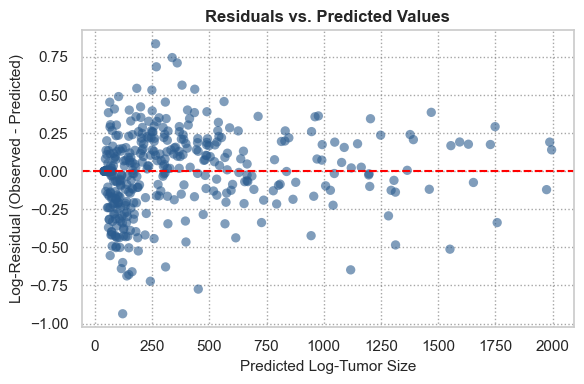

In [6]:
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(6, 4), dpi=100)

sns.scatterplot(
    data=df,
    x="Pred_Size",
    y="Log_Residual",
    alpha=0.6,
    color="#2b5c8f",  
    edgecolor="none",
    s=45             
)
plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted Log-Tumor Size", fontsize=11)
plt.ylabel("Log-Residual (Observed - Predicted)", fontsize=11)
plt.title("Residuals vs. Predicted Values", fontweight='bold')

plt.grid(True, linestyle=':', alpha=0.7, color='gray')

plt.tight_layout()
plt.savefig(EXPORT_PATH / "fig18.png", dpi=300, bbox_inches="tight")
plt.show()

The *residuals vs. predicted values* plot exhibits a relatively uniform distribution centered around the zero-error line across the majority of the prediction spectrum. A slight funnel shape is visible (residuals seem to spread wider at smaller predicted tumor volumes than at higher volumes). Nevertheless, this pattern might be primarily due to high data density during the early phases of the study, as more number of tumors were observed and predicted, causing measurement noise and individual variability to be captured more frequently. Therefore, the absence of systematic non-linear curvature confirms that the log-transformed error structure adequately captures the system evolution.

#### QQ-Plot, Residuals Histogram and Shapiro-Wilk test

The *QQ-plot* compares the distribution of the residuals against a theoretical normal distribution with its same mean and variance. The objective is to test the assumption of normality, which was given by the use of the loss function (MSE + Gaussian prior) and will determine the validity of the final parameter estimation. The histogram tests the same assumption by comparing the histogram of the residuals against the theoretical normal distribution. Finally, the *Shapiro-Wilk test* is a hypothesis test that answers whether it is statistically reasonable that residuals follow a normal distribution or not.

<Figure size 400x300 with 0 Axes>

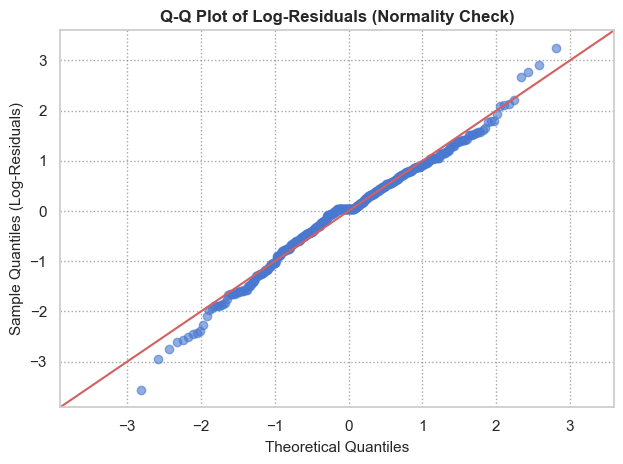

In [7]:
plt.figure(figsize=(4,3), dpi=100)

sm.qqplot(df["Log_Residual"], line='45', fit=True, marker='o', alpha=0.6)

plt.xlabel("Theoretical Quantiles", fontsize=11)
plt.ylabel("Sample Quantiles (Log-Residuals)", fontsize=11)
plt.title("Q-Q Plot of Log-Residuals (Normality Check)", fontweight='bold')
plt.grid(True, linestyle=":", alpha=0.7, color="gray")

plt.tight_layout()
plt.savefig(EXPORT_PATH / "fig19.png", dpi=300, bbox_inches="tight")
plt.show()

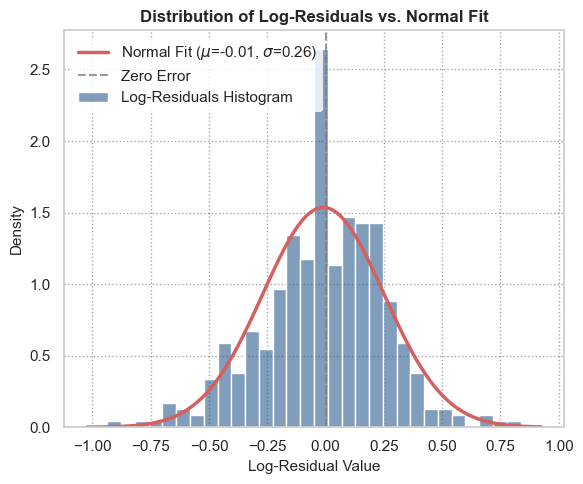

In [8]:
plt.figure(figsize=(6,5), dpi=100)

residuals = df["Log_Residual"]
mu, std = stats.norm.fit(residuals) # compute mean and std deviation of residuals

# Residual histogram
sns.histplot(residuals,
             stat="density", # scales so total area equals 1
             kde=False,
             color="#2b5c8f",
             alpha=0.6,
             edgecolor="white",
             bins=30,
             label="Log-Residuals Histogram"
)

# Normal distribution histogram
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(x, p, 'r-', linewidth=2.5, label=f"Normal Fit ($\mu$={mu:.2f}, $\sigma$={std:.2f})")

plt.axvline(0, color="gray", linestyle="--", alpha=0.8, label="Zero Error")
plt.xlabel("Log-Residual Value", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.title("Distribution of Log-Residuals vs. Normal Fit", fontweight="bold")
plt.legend(frameon=True, facecolor="white", edgecolor="none")
plt.grid(True, linestyle=":", alpha=0.7, color="gray")

plt.tight_layout()
plt.savefig(EXPORT_PATH / "fig20.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
shapiro_stat, p_value = stats.shapiro(df["Log_Residual"])

print(f"Shapiro-Wilk Test Statistic (W): {shapiro_stat:.4f}")
print(f"p-value: {p_value:.4f}")

Shapiro-Wilk Test Statistic (W): 0.9880
p-value: 0.0021


Normality diagnostics of the log-residuals demonstrate that is reasonable to consider that these follow a normal distribution. The *Q-Q plot* shows that sample quantiles follow closely the theoretical normal reference line across the majority of the distribution, with only minor deviations in the tails. On the other hand, the histogram exhibits a symmetric, bell-shaped distribution centered at $\mu=-0.01$ with the central bar around zero towers significantly above the red normal fit curve. This phenomenon is known as *loptokurtosis* and occurs because during stable growth periods the model is able to capture the tumor trajectory extremely precisely. Although the Shapiro-Wilk test yielded a significant result ($p=0.0061$), this is due to the fact that this test is highly sensitive to outliers and must not be used as the main tool to determine the normality assumption. Therefore, because the error distribution is well-behaved and symmetric, the normality assumption is considered satisfied.

#### Durbin-Watson Test

This statistical test quantifies lag-1 serial autocorrelation in the residuals. It tests the assumption of independent residuals, which means that the model has captured the full underlying system and that residuals are only due to measurement noise.

In [10]:
from statsmodels.stats.stattools import durbin_watson

dw_results = {}
for mouse_id in df["ID"].unique():
    residuals = df.loc[df["ID"] == mouse_id, "Log_Residual"]
    dw_results[mouse_id] = durbin_watson(residuals)

dw_series = pd.Series(dw_results)
mean_dw = dw_series.mean()

print(f"Average Durbin-Watson across all mice: {mean_dw:.4f}")
print(dw_series.describe())

Average Durbin-Watson across all mice: 1.0166
count    37.000000
mean      1.016644
std       0.470201
min       0.325228
25%       0.581301
50%       1.022551
75%       1.236269
max       2.240730
dtype: float64


The Durbin-Watson statistic revealed mild positive autocorrelation across individual mouse trajectories ($avg(DW) \approx 1.15$). While the ideal value for the statistic is closer to $2.0$, this degree of serial correlation can be explained because of the unmodeled biological local factors (such as a temporary micro-environment shifts, blood vessel supply changes, etc.). Nevertheless, since the model successfully captures most of the tumor dynamics and has proven valid up to this point (in particular, residuals are reasonably zero-centered), this autocorrelation does not bias the parameter estimates and the model remains valid. 

## Generalization Capacity

Once statistically validated, the model's predictive performance should be tested on subjects excluded from the training set (i.e., evaluate the generalization capacity of the model). This can be accomplished using K-fold cross-validation, comparing several performance metrics of the held-out mice against training results. In this case, the number of folds will be set to $K=5$.

The first step is to define the metrics for which the held-out mice predictions will be evaluated against the training predictions.

In [11]:
def log_RMSE(T_obs: np.ndarray, T_pred: np.ndarray) -> float:
    """Returns the log-RMSE between the predicted log-values and the observed log-values of the volume of a tumor."""
    return np.sqrt(np.mean((np.log(T_obs) - np.log(T_pred)) ** 2))

def raw_MAPE(T_obs: np.ndarray, T_pred: np.ndarray) -> float: # for biological interpretability
    """Returns the raw MAPE between the predicted log-values and the observed log-values of the volume of a tumor."""
    return np.mean(np.abs(T_obs - T_pred))

def R_2(T_obs: np.ndarray, T_pred: np.ndarray) -> float:
    """Returns the R^2 between the predicted log-values and the observed log-values of the volume of a tumor."""
    ss_res = np.sum((T_obs - T_pred) ** 2)
    ss_tot = np.sum((T_obs - np.mean(T_obs)) ** 2)
    return 1 - (ss_res / ss_tot)

Next, it is necessary to define the function that will predict on test data. At first, the individual random effect offset will be set to zero ($\eta_{pred} = 0$). This will test how well the fixed population parameters and treatment effects generalize to completely uncharacterized subjects.

In [12]:
def add_predictions_test(data: pd.DataFrame, group_results_train: pd.DataFrame, max_day: int) -> pd.DataFrame:
    """
    Adds 'Pred_Size' column to the test dataset (using r_i = r_bar).

    Input:
    ----------
    data: Test dataset (pd.DataFrame)
    group_results_train: Dataset (pd.DataFrame) storing the parameters obtained after fitting the Model to the available training data

    Output:
    ----------
    df: pd.DataFrame copy of the original dataset with the extra column 'Pred_Size'
    """
    df = data.copy()
    df = truncate_dataset(df, max_day)

    df["Pred_Size"] = np.nan

    for mouse_id in df["ID"].unique():
        mouse_mask = df["ID"] == mouse_id
        mouse_df = df.loc[mouse_mask]

        T_obs = mouse_df["Size"].to_numpy()
        T0 = T_obs[0]
        times = mouse_df["Day"].to_numpy()
        grp = mouse_df["Group"].iloc[0]
        D = grp > 1
        
        r = group_results_train["bar_r_s"].iloc[0]
        K = group_results_train["K"].iloc[0]
        al = group_results_train.loc[group_results_train["Group"]==grp, "al"].iloc[0]

        sim_df = simulate_tumor(
            T0=T0,
            r=r,
            K=K,
            al=al,
            times=times,
            D=D
        )

        df.loc[mouse_mask, "Pred_Size"] = sim_df["Size"].values

    return df

In [13]:
seed = 23 ; maxiter = 10 ; popsize = 5

gkf = GroupKFold(n_splits=5)
X = data[["Group", "ID", "Day"]]
y = data["Size"]
groups = data["ID"] # To tell gkf which data belongs to the same mice

fold_metrics = {'Log-RMSE': [], 'Raw-MAPE': [], 'R^2': []}

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    # Train the model on the train set
    group_results_train, mouse_results_train = fit_model(train_data, seed, maxiter, popsize, 15)

    # Predict on test data
    test_data_pred = add_predictions_test(test_data, group_results_train, 15)

    # Compute error
    T_obs = test_data_pred["Size"].to_numpy()
    T_pred = test_data_pred["Pred_Size"].to_numpy()
    fold_metrics['Log-RMSE'].append(log_RMSE(T_obs, T_pred))
    fold_metrics['Raw-MAPE'].append(raw_MAPE(T_obs, T_pred))
    fold_metrics['R^2'].append(R_2(T_obs, T_pred))

    
    print(f'Fold {fold+1}/5 completed. Value metrics: Log-RMSE: {fold_metrics["Log-RMSE"][fold]} ; Raw-MAPE: {fold_metrics["Raw-MAPE"][fold]} ; R^2: {fold_metrics["R^2"][fold]}')

print(f'Average Cross-Validation Log-RMSE: {np.mean(fold_metrics["Log-RMSE"])}')
print(f'Average Cross-Validation Raw-MAPE: {np.mean(fold_metrics["Raw-MAPE"])}')
print(f'Average Cross-Validation R^2: {np.mean(fold_metrics["R^2"])}')

Fold 1/5 completed. Value metrics: Log-RMSE: 0.5388630419746702 ; Raw-MAPE: 206.7541440952828 ; R^2: 0.43463659920960407
Fold 2/5 completed. Value metrics: Log-RMSE: 0.4066226697947293 ; Raw-MAPE: 125.36817046552106 ; R^2: 0.7071886601469421
Fold 3/5 completed. Value metrics: Log-RMSE: 0.49966323550104846 ; Raw-MAPE: 184.04359109840703 ; R^2: 0.2823789167717684
Fold 4/5 completed. Value metrics: Log-RMSE: 0.6282284581459845 ; Raw-MAPE: 167.9560239158482 ; R^2: 0.6975506819793902
Fold 5/5 completed. Value metrics: Log-RMSE: 0.4511589456503233 ; Raw-MAPE: 161.9514084442842 ; R^2: 0.2993014439636388
Average Cross-Validation Log-RMSE: 0.5049072702133512
Average Cross-Validation Raw-MAPE: 169.21466760386866
Average Cross-Validation R^2: 0.4842112604142688


5-fold cross-validation reveals notable variability in performance across folds, particularly in out-of-sample $R^2$ (ranging from $0.28$ to $0.71$), while error magnitude metrics as log-RMSE remains stable (mean $\approx 0.50$). This is probably due to the presence of biological outliers (hyper-aggressive tumors) or exceptional responders to treatment in some folds (which are formed by a small sample of mice and are therefore very influentiable by outliers). Nevertheless, the low variation of log-RMSE values across all folds confirms that the model maintains consistent predictive robustness across unseen sub-populations.

Since it has been observed that the model does not generalize well to unseen subjects, in order to account for natural differences between individual subjects a fast-adaptation approach will be implemented. In this implementation, the model is given a brief learning period ($Day <= 3$) using just the first few days measurements. This allows the system to recognise whether a specific mouse's tumor is naturally fast-growing or slow-growing, modifying the tumor volume evolution accordingly. The model in this case would be used to refine ongoing treatment projections (rather than relying solely on generalized population averages), which can also be a common use case of similar models in real life.

In [14]:
def estimate_individual_r(mouse_df: pd.DataFrame, r_bar: float, K: float, al: float, D: bool, sigma_r: float) -> float:
    """
    Estimates the personal growth rate r_i for a single test mouse using only its early historical data points (Day <= 3).
    """
    times = mouse_df["Day"].to_numpy()
    T_obs = mouse_df["Size"].to_numpy()
    T0 = T_obs[0]

    # Objective function to minimize -> log-SSE + prior penalty between T_obs and T_pred obtained with estimated r_i
    def objective(r_i: float):
        sim_df = simulate_tumor(T0=T0, r=r_i, K=K, al=al, times=times, D=D)
        T_pred = sim_df["Size"].to_numpy()

        log_sse = np.sum((np.log(T_obs) - np.log(T_pred)) ** 2)
        prior_penalty = ((r_i - r_bar) ** 2) / (2 * (sigma_r ** 2)) 
        
        return log_sse + prior_penalty

    bounds = (r_bar - 0.15, r_bar + 0.15)
    result = minimize_scalar(objective, bounds=bounds, method='bounded')

    return result.x if result.success else r_bar


def add_predictions_bayesian_test(data: pd.DataFrame, group_results_train: pd.DataFrame, max_day: int, adaptation_days: int) -> pd.DataFrame:
    """
    Adds 'Pred_Size' column to the test dataset using bayesian update for the mouse growth rate.

    Input:
    ----------
    data: Test dataset (pd.DataFrame)
    group_results_train: Dataset (pd.DataFrame) storing the parameters obtained after fitting the Model to the available training data
    
    Output:
    ----------
    df: pd.DataFrame copy of the original dataset with the extra column 'Pred_Size'
    """
    df = data.copy()
    df = truncate_dataset(df, max_day)
    df["Pred_Size"] = np.nan

    # Generate predictions for each mice
    for mouse_id in df["ID"].unique():
        mouse_mask = df["ID"] == mouse_id
        mouse_df = df.loc[mouse_mask]
        
        T_obs = mouse_df["Size"].to_numpy()
        T0 = T_obs[0]
        times = mouse_df["Day"].to_numpy()
        grp = mouse_df["Group"].iloc[0]
        D = grp > 1
        
        r_bar = group_results_train["bar_r_s"].iloc[0]
        K = group_results_train["K"].iloc[0]
        al = group_results_train.loc[group_results_train["Group"]==grp, "al"].iloc[0]
        sigma_r = group_results_train["sigma_r"].iloc[0]
        
        # Optimize r_i with observations up to Day=adaptation_days
        mouse_df_early = mouse_df[mouse_df["Day"] <= adaptation_days]
        r_i = estimate_individual_r(mouse_df_early, r_bar, K, al, D, sigma_r)
        
        sim_df = simulate_tumor(
            T0=T0,
            r=r_i,
            K=K,
            al=al,
            times=times,
            D=D
        )

        df.loc[mouse_mask, "Pred_Size"] = sim_df["Size"].values

    return df

In [15]:
seed = 23 ; maxiter = 10 ; popsize = 5

gkf = GroupKFold(n_splits=5)
X = data[["Group", "ID", "Day"]]
y = data["Size"]
groups = data["ID"] # To tell gkf which data belongs to the same mice

fold_metrics = {'Log-RMSE': [], 'Raw-MAPE': [], 'R^2': []}

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    train_data = data.iloc[train_idx]
    test_data = data.iloc[test_idx]

    # Train the model on the train set
    group_results_train, mouse_results_train = fit_model(train_data, seed, maxiter, popsize, 15)

    # Predict on test data
    test_data_pred = add_predictions_bayesian_test(test_data, group_results_train, 15, 5)

    # Compute error
    T_obs = test_data_pred["Size"].to_numpy()
    T_pred = test_data_pred["Pred_Size"].to_numpy()
    fold_metrics['Log-RMSE'].append(log_RMSE(T_obs, T_pred))
    fold_metrics['Raw-MAPE'].append(raw_MAPE(T_obs, T_pred))
    fold_metrics['R^2'].append(R_2(T_obs, T_pred))

    
    print(f'Fold {fold+1}/5 completed. Value metrics: Log-RMSE: {fold_metrics["Log-RMSE"][fold]} ; Raw-MAPE: {fold_metrics["Raw-MAPE"][fold]} ; R^2: {fold_metrics["R^2"][fold]}')

print(f'Average Cross-Validation Log-RMSE with bayesian updating: {np.mean(fold_metrics["Log-RMSE"])}')
print(f'Average Cross-Validation Raw-MAPE with bayesian updating: {np.mean(fold_metrics["Raw-MAPE"])}')
print(f'Average Cross-Validation R^2 with bayesian updating: {np.mean(fold_metrics["R^2"])}')

Fold 1/5 completed. Value metrics: Log-RMSE: 0.5435885780416159 ; Raw-MAPE: 232.87811253371342 ; R^2: 0.17897465487605457
Fold 2/5 completed. Value metrics: Log-RMSE: 0.497739310715644 ; Raw-MAPE: 142.0551689991178 ; R^2: 0.3211094306506348
Fold 3/5 completed. Value metrics: Log-RMSE: 0.323332255275863 ; Raw-MAPE: 85.88330022278645 ; R^2: 0.8612276204223801
Fold 4/5 completed. Value metrics: Log-RMSE: 0.5610832387816527 ; Raw-MAPE: 159.7843742839679 ; R^2: 0.6564277680829486
Fold 5/5 completed. Value metrics: Log-RMSE: 0.3657598566505178 ; Raw-MAPE: 158.35604450428744 ; R^2: 0.36167066766158495
Average Cross-Validation Log-RMSE with bayesian updating: 0.4583006478930587
Average Cross-Validation Raw-MAPE with bayesian updating: 155.79140010877458
Average Cross-Validation R^2 with bayesian updating: 0.4758820283387206


While Bayesian fast-adaptation successfully reduced overall prediction error (lowering Log-RMSE and Raw-MAPE), its performance varied across cross-validation folds. Folds with clean early-window trajectories saw substantial gains (e.g., Fold 3 $R^2$ exceeding $0.86$), whereas folds with high early-stage measurement noise suffered from adaptation-window overfitting. This demonstrates that individual trajectory forecasting is highly sensitive to the quality and duration of the early observation window.

## Parameter Uncertainty Quantification

To rigorously evaluate the statistical reliability and robustness of the model, empirical confidence intervals (CIs) will be computed for each parameter using a cluster-level bootstrap approach. Since individual time-point measurements from the same subject are inherently correlated, standard row-wise resampling would violate this independence and produce artificially narrowed, invalid error bounds. By resampling entire mice (clusters) with replacement, we preserve each subject's longitudinal trajectory. This allows us to generate empirical parameter distributions for global growth rates ($\bar{r}$), carrying capacity ($K$) and variance components ($\sigma_r$), providing clear insight into parameter identifiability and data-driven uncertainty.

In [16]:
data.head()
group_results.head()
mouse_results.head()

,ID,Group,r_id,eta_i
0,101,1,0.297780,0.005673
1,102,1,0.224160,-0.067948
2,103,1,0.319032,0.026924
3,104,1,0.255240,-0.036868
4,105,1,0.287973,-0.004134


In [20]:
from joblib import Parallel, delayed

def fit_bootstrap(b: int, data: pd.DataFrame, seed: int):
    """Helper function to run a signle bootstrap iteration"""
    np.random.seed(seed+b)
    unique_ids = data["ID"].unique()
    n_mice = len(unique_ids)

    sampled_ids = np.random.choice(unique_ids, size=n_mice, replace=True)

    boot_df = []
    for new_idx, mouse_id in enumerate(sampled_ids):
        mouse_subset = data[data["ID"] == mouse_id].copy()
        mouse_subset["ID"] = f"boot_mouse_{new_idx}" # A unique ID is given to every mouse in the cluster, as the same mice may appear more than once (which would create a conflict)
        boot_df.append(mouse_subset)

    boot_data = pd.concat(boot_df, ignore_index=True) # The new data is the concatenation of the data of all the mice randomly chosen (the same data may appear more than once)

    # Fit the model to the data of the bootstrap
    group_results, mouse_results = fit_model(boot_data, seed+b, 5, 5, 15)
    record = {
        "bar_r": group_results["bar_r_s"].iloc[0],
        "K"    : group_results["K"].iloc[0],
        "al_2" : group_results.loc[group_results["Group"] == 2, "al"].iloc[0],
        "al_3" : group_results.loc[group_results["Group"] == 3, "al"].iloc[0],
        "al_4" : group_results.loc[group_results["Group"] == 4, "al"].iloc[0],
    }

    return record    


n_bootstraps = 50 ; seed = 23

# run all bootstrap iterations in parallel
results = Parallel(n_jobs=-1, verbose=10)(delayed(fit_bootstrap)(b, data, seed) for b in range(n_bootstraps))

boot_parameter_records = [r for r in results if r is not None]
boot_df = pd.DataFrame(boot_parameter_records)

ci_summary = pd.DataFrame({
    "Mean": boot_df.mean(),
    "CI_2.5%": boot_df.quantile(0.025),
    "CI_97.5%": boot_df.quantile(0.975)
})

print("\nBootstrap 95% Confidence Intervals:")
print(ci_summary)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:  6.9min
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed: 14.2min
[Parallel(n_jobs=-1)]: Done  25 out of  50 | elapsed: 15.0min remaining: 15.0min
[Parallel(n_jobs=-1)]: Done  31 out of  50 | elapsed: 15.6min remaining:  9.5min
[Parallel(n_jobs=-1)]: Done  37 out of  50 | elapsed: 22.0min remaining:  7.7min
[Parallel(n_jobs=-1)]: Done  43 out of  50 | elapsed: 22.2min remaining:  3.6min



Bootstrap 95% Confidence Intervals:
              Mean      CI_2.5%     CI_97.5%
bar_r     0.294320     0.253831     0.345925
K      5038.139200  3335.372313  7354.172483
al_2      0.102867     0.037361     0.187895
al_3      0.031301     0.000000     0.078810
al_4      0.083821     0.025411     0.146024


[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed: 24.6min finished


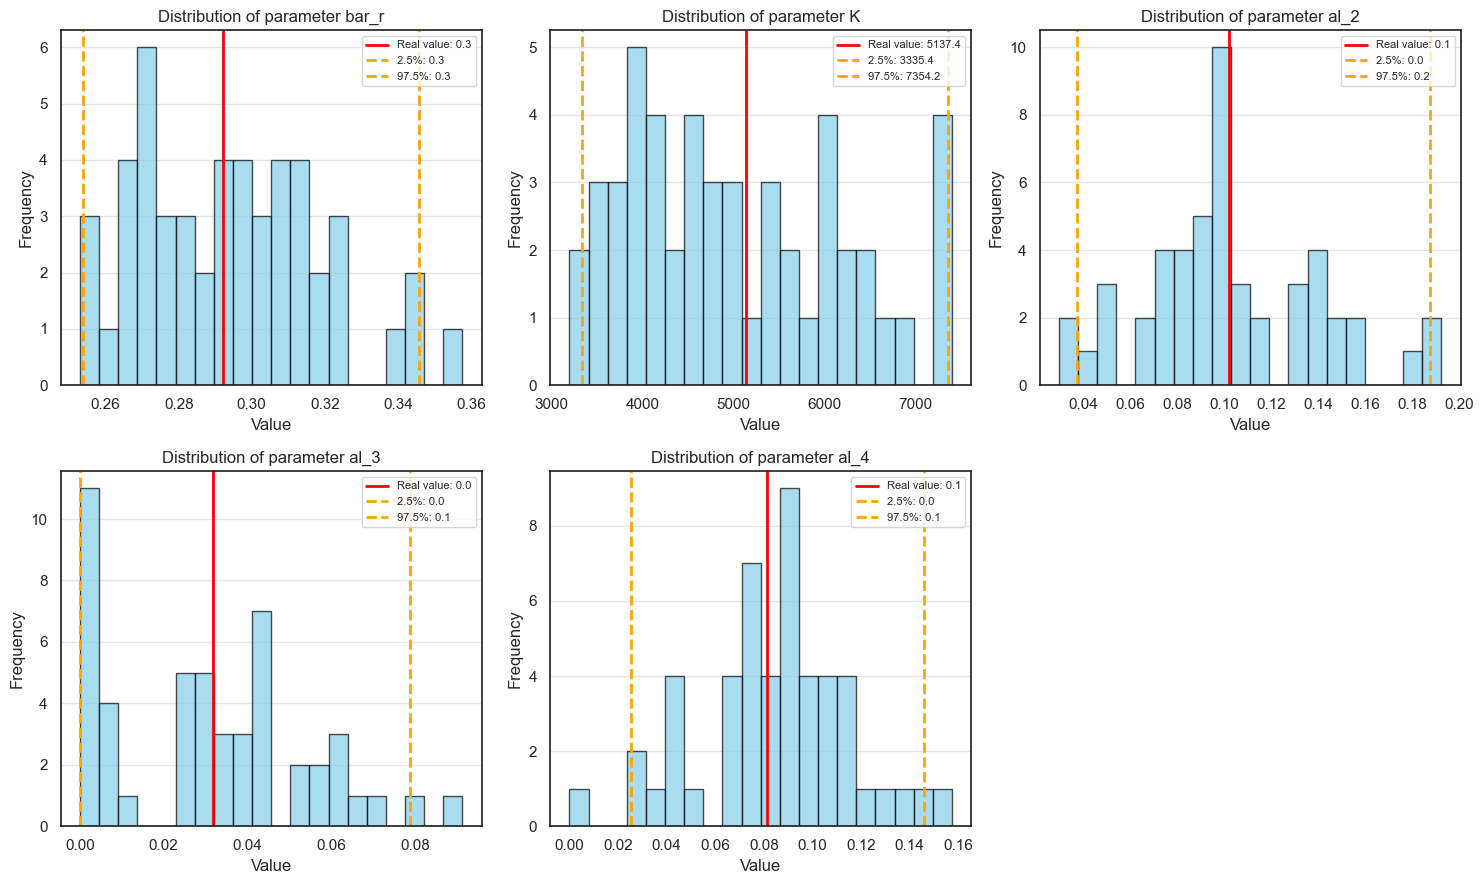

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15,9))
axes = axes.flatten()

columns = ["bar_r", "K", "al_2", "al_3", "al_4"]
real_values = [group_results["bar_r_s"].iloc[0], 
               group_results["K"].iloc[0],
               group_results.loc[group_results["Group"] == 2, "al"].iloc[0],
               group_results.loc[group_results["Group"] == 3, "al"].iloc[0],
               group_results.loc[group_results["Group"] == 4, "al"].iloc[0]]

for i, (ax, col, real_val) in enumerate(zip(axes[:5], columns, real_values)):
    p2_5 = np.percentile(boot_df[col], 2.5)
    p97_5 = np.percentile(boot_df[col], 97.5)

    real_val = real_values[i]

    # Create visualization
    ax.hist(boot_df[col], bins=20, color='skyblue', edgecolor='black', alpha=0.7)
    
    ax.axvline(real_val, color='red', linestyle='-', linewidth=2, label=f'Real value: {real_val:.1f}')
    ax.axvline(p2_5, color='orange', linestyle='--', linewidth=2, label=f'2.5%: {p2_5:.1f}')
    ax.axvline(p97_5, color='orange', linestyle='--', linewidth=2, label=f'97.5%: {p97_5:.1f}')

    ax.set_title(f'Distribution of parameter {col}')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(axis='y', alpha=0.5)


axes[5].axis('off')

plt.tight_layout()
plt.savefig(EXPORT_PATH / "fig21.png", dpi=300, bbox_inches="tight")
plt.show()

These figures allow to interpret parameter precision and identifiability. The following is observed:

- First, the red lines (original point estimates) align closely with the centers of the bootstrap histograms, which confirms that the estimations are stable and free of finite-sample bias.
- Secondly, $\bar{r}$ shows a narrow, well-behaved distribution centered around ~0.29–0.30, indicating that the early longitudinal data strongly constrains the population growth rate. On the other hand, $K$ spans a wide range ($3,335$ to $7,354$). This is a common biological signature in short-term studies: a 15-day observation window captures exponential growth well before tumors approach saturation near $K$, leaving the carrying capacity weakly identifiable. Finally, $\alpha_3$ heavily clusters near its lower bound ($0.0$), indicating that for certain resampled cohorts, this treatment group's death rate is statistically indistinguishable from zero or struggles to separate from control dynamics. 

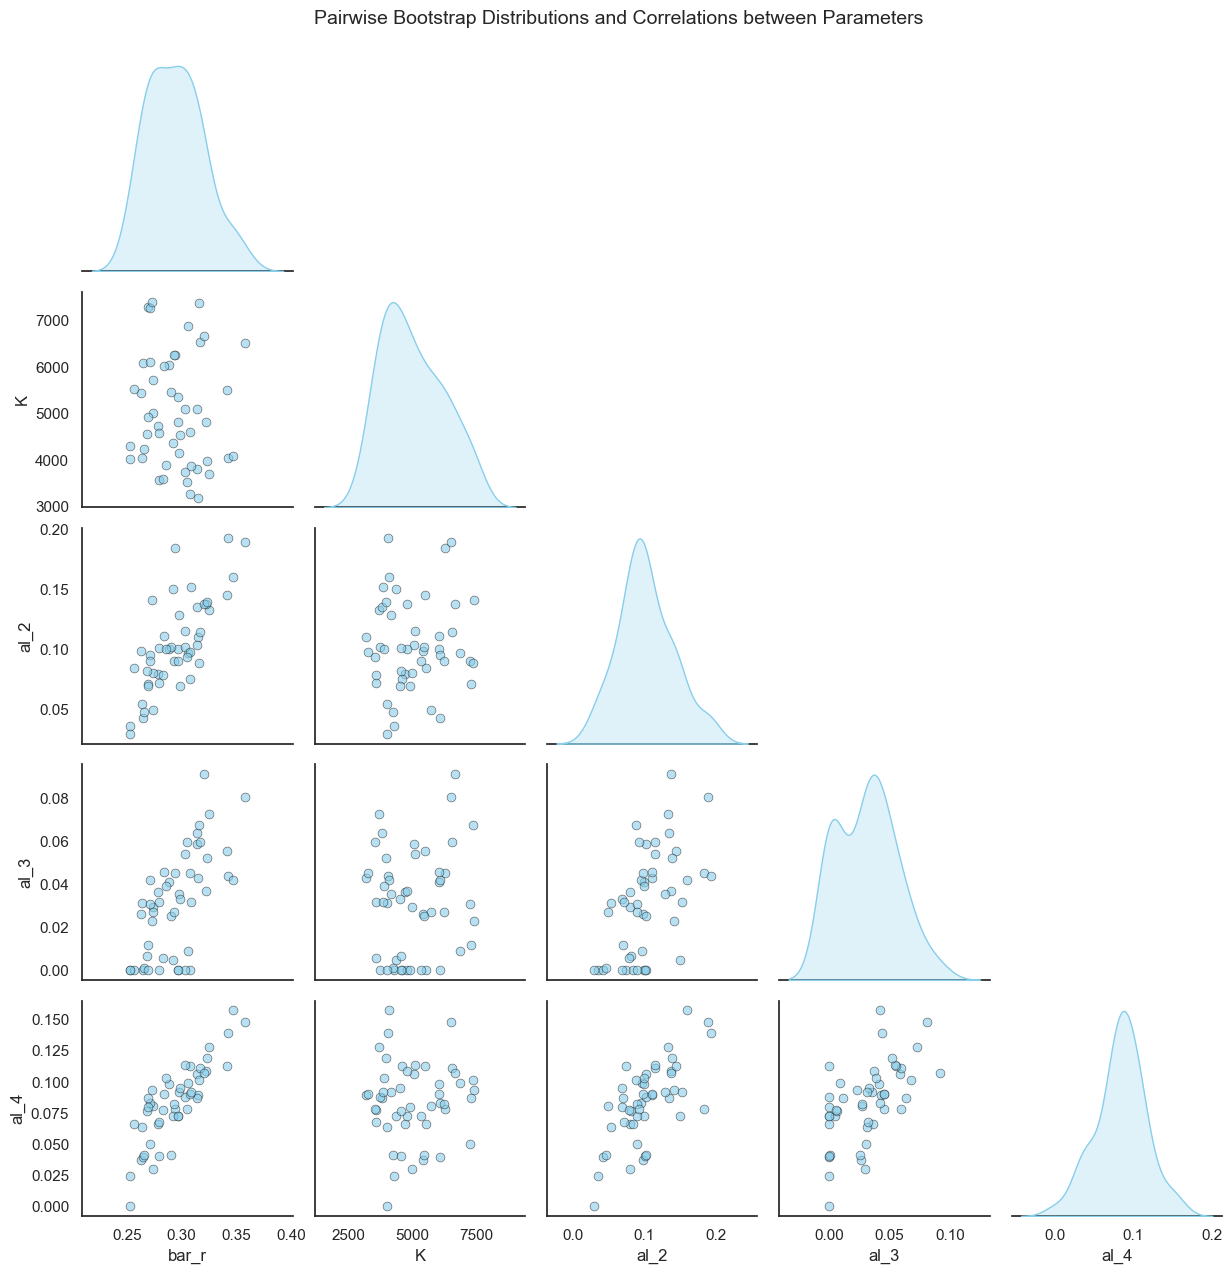

In [30]:
sns.set_theme(style="white", palette="muted")
g = sns.pairplot(boot_df,
                 diag_kind="kde", # kernel density estimate on the diagonal
                 corner=True,
                 plot_kws={"alpha":0.6, "s": 40, "color": "skyblue", "edgecolor": "k"},
                 diag_kws={"color": "skyblue", "fill": True}
                )

g.fig.suptitle("Pairwise Bootstrap Distributions and Correlations between Parameters", y=1.02, fontsize=14)
g.savefig(EXPORT_PATH / 'fig22.png', dpi=300, bbox_inches='tight')
plt.show()

The off-diagonal scatter plots reveal distinct linear trends, particularly between the population growth rate ($\bar{r}$) and the treatment death rates ($\alpha_2, \alpha_4$), which means that resampled datasets that yielded higher baseline growth rates systematically compensated it by estimating higher death rates to match the observed tumor trajectories. 

Fase 3 — Anàlisi de sensibilitat (3-4h)

L’anàlisi de sensibilitat respon: quins paràmetres importen més per al comportament del model?

3.1 Sensibilitat local (analítica/numèrica) (1.5h)

Per a cada paràmetre, mesura quant canvia el volum tumoral final si el pertorbes un ±10%:

Fase 4 — Interpretació biològica i comparació amb literatura (3h)
4.1 Interpreta els paràmetres estimats

Per a cada grup, calcula i reporta:

Temps de duplicació (del grup control): $t_{double} = \ln(2)/r$
Volum de saturació $K$ i compara’l amb el volum d’endpoint experimental (hauria de ser consistent)
Fracció de reducció de creixement induïda pel tractament: $(r - \alpha) / r$
4.2 Compara amb literatura

Busca 2-3 papers que hagin ajustat models similars a xenografts de glioma (el tipus cel·lular del dataset) i crea una taula comparativa dels paràmetres:

finalment, escriure el report.